<a href="https://colab.research.google.com/github/vthkrl/big_data_fall26/blob/main/Civil_Planning_Model_Will.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

3. Model training: train a machine learning model on the raw scores for the quality of life domains of each district, so that the model determines how the count of a facility type in a district may affect the raw scores of domains for that district.


In [60]:
import numpy as np
import pandas as pd
from scipy.optimize import Bounds, LinearConstraint, milp
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split, GroupShuffleSplit, GroupKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler, PolynomialFeatures, OrdinalEncoder

from google.colab import drive
drive.mount('/content/drive')
folder_path = "/content/drive/MyDrive/Project/datasets/"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [61]:
trainer_path = folder_path + "trainer.csv"
trainer = pd.read_csv(trainer_path)

survey_path = folder_path + "survey.csv"
survey = pd.read_csv(survey_path)

In [62]:
# define columns
target_col = "OverallQuality"
id_cols = ["GeoID", "TimePeriod"]
facility_cols = [c for c in trainer.columns if c not in id_cols + [target_col]]

print(f"Detected {len(facility_cols)} facility types:", facility_cols)

# train/test split
X = trainer[id_cols + facility_cols]
y = trainer[target_col]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=50
)

# build preprocessor
# OrdinalEncoder converts GeoID and TimePeriod into integer categories for tree splits
preprocessor = ColumnTransformer([
    (
        "cat",
        OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1),
        id_cols,
    ),
    ("num", "passthrough", facility_cols),
])

# set monotonic constraints
# 0 = unconstrained (GeoID and TimePeriod can push baseline up or down freely)
# 1 = monotonic increasing (adding facilities can never decrease predicted quality)
monotonic_constraints = [0] * len(id_cols) + [1] * len(facility_cols)

# build and fit model
model = Pipeline([
    ("prep", preprocessor),
    (
        "regressor",
        HistGradientBoostingRegressor(
            categorical_features=list(range(len(id_cols))),
            monotonic_cst=monotonic_constraints,
            max_iter=55,
            learning_rate=0.1,
            max_leaf_nodes=20,
            min_samples_leaf=1,
            l2_regularization=1.0,
            random_state=42,

        ),
    ),
])

model.fit(X_train, y_train)

# evaluate model fit
preds = np.clip(model.predict(X_test), 0, 1)
print(f"Test R-squared: {r2_score(y_test, preds):.4f}")

cv_rmse = -cross_val_score(
    model, X, y, cv=5, scoring="neg_root_mean_squared_error"
)
print(f"5-Fold CV RMSE: {cv_rmse.mean():.4f} ± {cv_rmse.std():.4f}")

Detected 25 facility types: ['ADULT SERVICES', 'CAMPS', 'CHILD SERVICES AND WELFARE', 'CITY AGENCY PARKING, MAINTENANCE, AND STORAGE', 'CULTURAL INSTITUTIONS', 'DAY CARE AND PRE-KINDERGARTEN', 'EMERGENCY SERVICES', 'HEALTH CARE', 'HIGHER EDUCATION', 'HISTORICAL SITES', 'HUMAN SERVICES', 'JUSTICE AND CORRECTIONS', 'LIBRARIES', 'MATERIAL SUPPLIES AND MARKETS', 'OFFICES, TRAINING, AND TESTING', 'OTHER PROPERTY', 'PARKS AND PLAZAS', 'PUBLIC SAFETY', 'SCHOOLS (K-12)', 'SOLID WASTE', 'TELECOMMUNICATIONS', 'TRANSPORTATION', 'VOCATIONAL AND PROPRIETARY SCHOOLS', 'WATER AND WASTEWATER', 'YOUTH SERVICES']
Test R-squared: 0.8307
5-Fold CV RMSE: 0.0806 ± 0.0085


In [63]:
def simulate_what_if(
    df, trained_model, geo_id, time_period, facility_to_add, delta=1
):
  # estimates how OverallQuality changes when 'delta' facilities are added.
  base_row = df[
      (df["GeoID"] == geo_id) & (df["TimePeriod"] == time_period)
  ].iloc[[0]]
  if base_row.empty:
    raise ValueError(
        f"No row found for GeoID={geo_id}, TimePeriod={time_period}"
    )

  base_score = trained_model.predict(base_row[id_cols + facility_cols])[0]

  cf_row = base_row.copy()
  cf_row[facility_to_add] = cf_row[facility_to_add] + delta
  new_score = trained_model.predict(cf_row[id_cols + facility_cols])[0]

  return {
      "GeoID": geo_id,
      "TimePeriod": time_period,
      "FacilityAdded": f"+{delta} {facility_to_add}",
      "BaselineScore": round(base_score, 4),
      "CounterfactualScore": round(new_score, 4),
      "EstimatedChange": round(new_score - base_score, 4),
  }


def optimize_new_facilities(
    df, trained_model, geo_id, time_period, max_new_facilities=5
):
  # finds the best mix of new facilities to maximize OverallQuality.
  base_row = df[
      (df["GeoID"] == geo_id) & (df["TimePeriod"] == time_period)
  ].iloc[[0]]
  base_score = trained_model.predict(base_row[id_cols + facility_cols])[0]

  # estimate marginal gain for adding +1 of each facility
  gains = []
  for fac in facility_cols:
    cf_row = base_row.copy()
    cf_row[fac] += 1
    new_score = trained_model.predict(cf_row[id_cols + facility_cols])[0]
    gains.append(new_score - base_score)

  # solve integer linear program to allocate up to 'max_new_facilities'
  res = milp(
      c=-np.array(gains),
      integrality=np.ones(len(facility_cols)),
      bounds=Bounds(0, max_new_facilities),
      constraints=LinearConstraint(
          np.ones((1, len(facility_cols))), 0, max_new_facilities
      ),
  )

  # evaluate exact combined counterfactual prediction
  opt_row = base_row.copy()
  added_counts = np.round(res.x).astype(int)
  for fac, add_qty in zip(facility_cols, added_counts):
    opt_row[fac] += add_qty

  final_score = trained_model.predict(opt_row[id_cols + facility_cols])[0]

  summary = pd.DataFrame({
      "Facility": facility_cols,
      "CurrentCount": [int(base_row[f].values[0]) for f in facility_cols],
      "RecommendedAdd": added_counts,
  })

  print(f"Baseline Score:  {base_score:.4f}")
  print(
      f"Optimized Score: {final_score:.4f} (Total Gain:"
      f" +{final_score - base_score:.4f})"
  )
  return summary[summary["RecommendedAdd"] > 0]

In [64]:
# example
sample_geo = trainer["GeoID"].iloc[0]
sample_time = trainer["TimePeriod"].iloc[0]
sample_fac = facility_cols[0]

print("What if example:")
print(
    simulate_what_if(
        trainer, model, sample_geo, sample_time, sample_fac, delta=2
    )
)
print()

print("Get best facility example:")
#  optimize adding up to 1 total new facilities
print(
    optimize_new_facilities(
        trainer, model, sample_geo, sample_time, max_new_facilities=1
    )
)
print()

What if example:
{'GeoID': np.int64(101), 'TimePeriod': '2009-13', 'FacilityAdded': '+2 ADULT SERVICES', 'BaselineScore': np.float64(0.8893), 'CounterfactualScore': np.float64(0.8893), 'EstimatedChange': np.float64(0.0)}

Get best facility example:
Baseline Score:  0.8893
Optimized Score: 0.9150 (Total Gain: +0.0258)
  Facility  CurrentCount  RecommendedAdd
1    CAMPS             7               1



In [65]:
def find_best_single_facility_per_row(df, trained_model, id_cols, facility_cols, delta=1):
    # evaluates adding 'delta' of each facility type for every row in 'df'
    # returns a summary DataFrame with the best facility to add per row.
    # fit the tuned pipeline on 100% of the data (all 532 rows)
    # this ensures every GeoID and TimePeriod is learned directly before predicting
    X_full = df[id_cols + facility_cols]
    y_full = df[target_col]
    model.fit(X_full, y_full)

    # generate baseline predictions bounded strictly between 0 and 1
    base_preds = np.clip(model.predict(X_full), 0, 1)

    # simulate adding 'delta' facilities of each type to find the best gain
    best_facilities = []
    best_gains = []

    # pre-compute predictions for each candidate facility
    gain_matrix = np.zeros((len(df), len(facility_cols)))

    for col_i, fac in enumerate(facility_cols):
        X_sim = X_full.copy()
        X_sim[fac] = X_sim[fac] + delta

        new_preds = np.clip(model.predict(X_sim), 0, 1)
        gain_matrix[:, col_i] = new_preds - base_preds

    # pick the facility with the highest predicted quality lift for each row
    best_col_indices = np.argmax(gain_matrix, axis=1)
    best_facilities = [facility_cols[i] for i in best_col_indices]
    best_gains = gain_matrix[np.arange(len(df)), best_col_indices]

    # build the clean output table
    result_df = df[id_cols + ["OverallQuality"]].copy()
    result_df["BaselinePredictedQuality"] = np.round(base_preds, 4)
    result_df["BestFacilityToAdd"] = best_facilities
    result_df["CurrentFacilityCount"] = [
        df.at[row_i, fac] for row_i, fac in enumerate(best_facilities)
    ]
    result_df["AddedCount"] = delta
    result_df["NewPredictedQuality"] = np.round(np.clip(base_preds + best_gains, 0, 1), 4)
    result_df["PredictedQualityLift"] = np.round(best_gains, 4)

    return result_df

4. Model execution: for each (district, facility type) pair, use the model to calculate the predicted domain scores, then calculate the predicted domain percentiles and the Predicted Overall Percentile Lift.


5. Civil planning: for each district, compare the Predicted Overall Percentile Lift of every facility type to determine which facility type would most improve the quality of life for that district, and for the city as a whole, compare the highest Predicted Overall Percentile Lift from each district to determine which facility types should be built and in which districts they should be built.


In [66]:
# run across all rows in trainer
best_trainer_facilities = find_best_single_facility_per_row(
    trainer, model, id_cols, facility_cols, delta=1
)

best_trainer_facilities.sort_values(by="PredictedQualityLift", ascending=False).head(10)

,GeoID,TimePeriod,OverallQuality,BaselinePredictedQuality,BestFacilityToAdd,CurrentFacilityCount,AddedCount,NewPredictedQuality,PredictedQualityLift
411,206,2015-19,0.175000,0.1677,CAMPS,0,1,0.3133,0.1456
54,206,2009-13,0.160776,0.1677,CAMPS,0,1,0.3133,0.1456
352,206,2014-18,0.155603,0.1677,CAMPS,0,1,0.3133,0.1456
232,206,2012-16,0.164224,0.1677,CAMPS,0,1,0.3133,0.1456
170,206,2011-15,0.150431,0.1677,CAMPS,0,1,0.3133,0.1456
112,206,2010-14,0.157759,0.1677,CAMPS,0,1,0.3133,0.1456
287,206,2013-17,0.155172,0.1677,CAMPS,0,1,0.3133,0.1456
290,202,2013-17,0.167241,0.1640,CAMPS,0,1,0.2921,0.1281
116,202,2010-14,0.153448,0.1640,CAMPS,0,1,0.2921,0.1281
174,202,2011-15,0.156466,0.1640,CAMPS,0,1,0.2921,0.1281


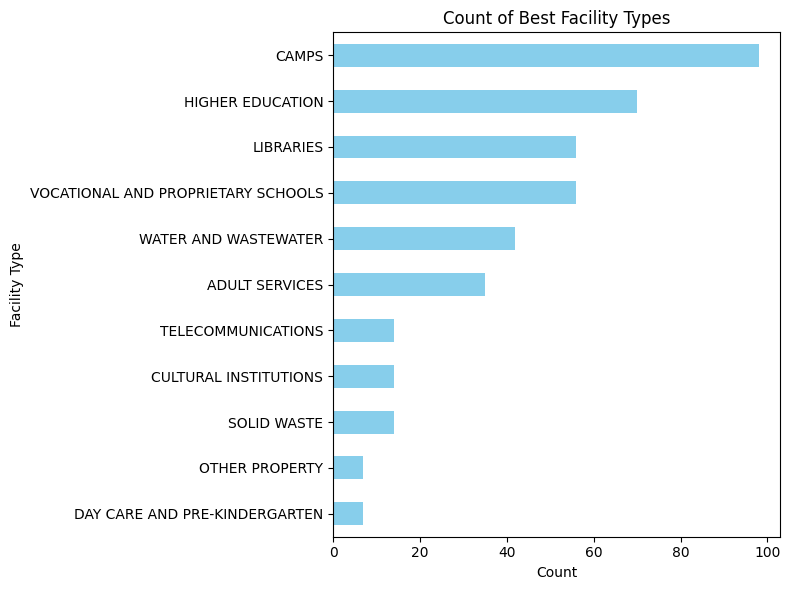

In [67]:
import matplotlib.pyplot as plt
ax = best_trainer_facilities['BestFacilityToAdd'].value_counts().plot(
    kind='barh', color='skyblue', figsize=(8, 6)
)

ax.invert_yaxis()  # Puts the highest count at the top
ax.set_title('Count of Best Facility Types')
ax.set_xlabel('Count')
ax.set_ylabel('Facility Type')

plt.tight_layout()
plt.show()

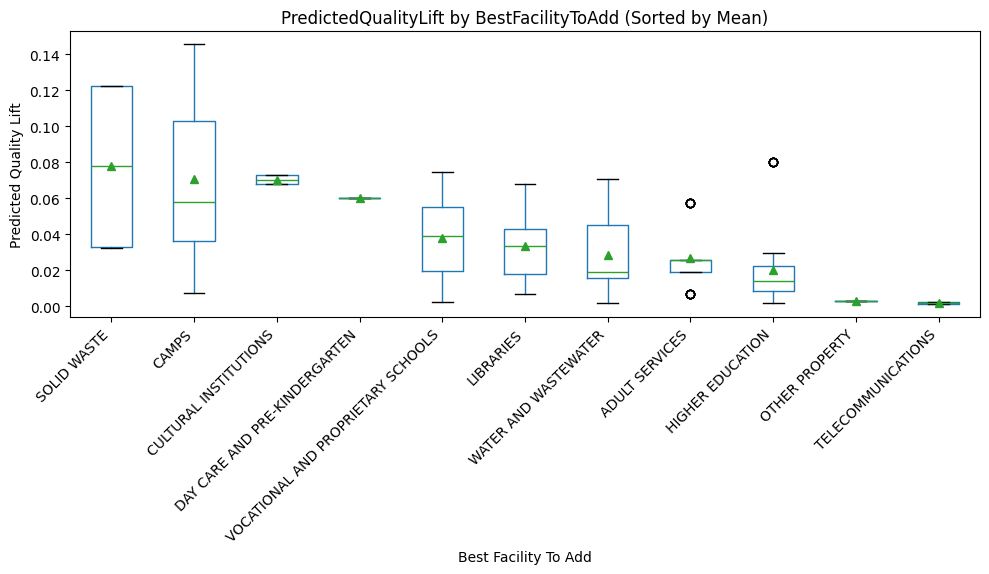

In [68]:
order = (
    best_trainer_facilities.groupby('BestFacilityToAdd')['PredictedQualityLift']
    .mean()
    .sort_values(ascending=False)
    .index
)

df_sorted = best_trainer_facilities.copy()
df_sorted['BestFacilityToAdd'] = pd.Categorical(
    df_sorted['BestFacilityToAdd'], categories=order, ordered=True
)

ax = df_sorted.boxplot(
    column='PredictedQualityLift',
    by='BestFacilityToAdd',
    showmeans=True,
    grid=False,
    figsize=(10, 6),
)

plt.title('PredictedQualityLift by BestFacilityToAdd (Sorted by Mean)')
plt.suptitle('')
plt.xlabel('Best Facility To Add')
plt.ylabel('Predicted Quality Lift')
plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()

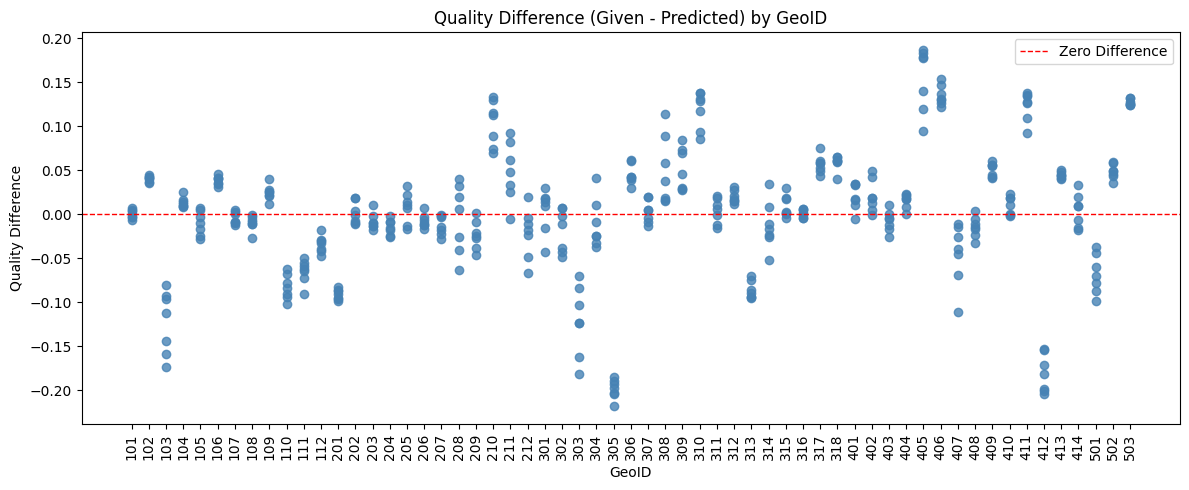

In [69]:
df_plot = best_trainer_facilities.copy()
df_plot['QualityDiff'] = (
    df_plot['OverallQuality'] - df_plot['BaselinePredictedQuality']
)
df_plot = df_plot.sort_values('GeoID')

plt.figure(figsize=(12, 5))
plt.scatter(
    df_plot['GeoID'].astype(str),
    df_plot['QualityDiff'],
    alpha=0.8,
    color='steelblue',
)
plt.axhline(0, color='red', linestyle='--', linewidth=1, label='Zero Difference')

plt.title('Quality Difference (Given - Predicted) by GeoID')
plt.xlabel('GeoID')
plt.ylabel('Quality Difference')
plt.xticks(rotation=90)
plt.legend()

plt.tight_layout()
plt.show()

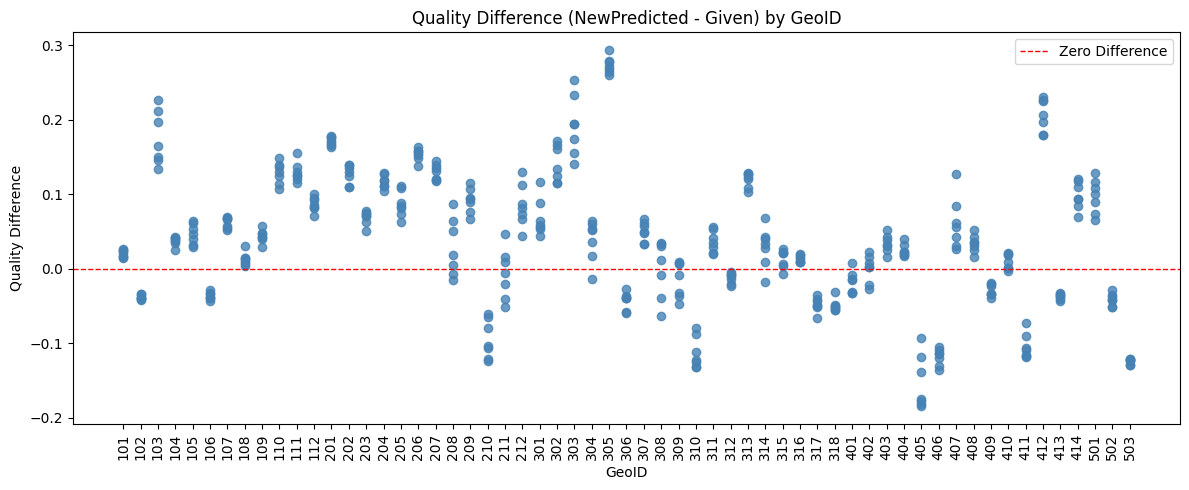

In [70]:
df_plot = best_trainer_facilities.copy()
df_plot['QualityDiff'] = (
    df_plot['NewPredictedQuality'] - df_plot['OverallQuality']
)
df_plot = df_plot.sort_values('GeoID')

plt.figure(figsize=(12, 5))
plt.scatter(
    df_plot['GeoID'].astype(str),
    df_plot['QualityDiff'],
    alpha=0.8,
    color='steelblue',
)
plt.axhline(0, color='red', linestyle='--', linewidth=1, label='Zero Difference')

plt.title('Quality Difference (NewPredicted - Given) by GeoID')
plt.xlabel('GeoID')
plt.ylabel('Quality Difference')
plt.xticks(rotation=90)
plt.legend()

plt.tight_layout()
plt.show()

In [71]:
output_path = folder_path + "best_facilities.csv"
best_trainer_facilities.to_csv(output_path, index=False)